# Laboratorio 6A · Del dato al conocimiento

En la Sesión 1, el conocimiento de un sistema experto lo escribía una persona, regla por regla. Aquí un algoritmo lo **induce** de casos ya resueltos. Usted lo hará con los 1309 pasajeros del **Titanic** y comparará lo que aprende un **árbol de decisión** con la regla del experto: «mujeres y niños primero». Después, con el **German Credit**, decidirá cuándo rechazar un crédito según el **costo del error**.

En este laboratorio usted:
* Inducirá un árbol de decisión y leerá sus reglas.
* Lo comparará con la regla del experto y con las de un LLM que no vio los datos.
* Medirá el **sobreajuste** con **validación cruzada**.
* Comparará el árbol con dos **ensambles**, que aciertan parecido y se explican peor.
* Elegirá el **umbral de decisión** de un crédito por su costo.

| | |
| :--- | :--- |
| **Resultados de aprendizaje** | RA2 (sistemas basados en conocimiento) y RA6 (técnicas de aprendizaje de máquina); RA8 en la sección 5 (un LLM frente a una técnica clásica). |
| **Tiempo** | 60 minutos en clase (secciones 0 a 6) y hasta 30 en casa (secciones 7.1 a 7.3 y 8, y las preguntas de casa); la 7.4 es del TI-1. En clase, escriba cada análisis en una frase. |
| **Modalidad** | En parejas. **No se escribe código:** se cambian números y textos en las celdas marcadas con ✏️. |
| **Antes de clase** | Ejecute en casa la primera celda: instala `scikit-learn` si falta, unos 40 MB. |
| **Entrega** | Este notebook ejecutado y el archivo `resultados_6A.csv`, al inicio de la semana 4 del curso (sección 8). |

## Contenido

* [Antes de empezar](#0) · *en clase, 6 min*
* [1 - Los pasajeros y la regla del experto](#1) · *en clase, 5 min*
* [2 - El primer árbol](#2) · *en clase, 11 min*
* [3 - ¿Qué tan profundo?](#3) · *en clase, 7 min*
* [4 - Muchos árboles votan, y la pregunta del auditor](#4) · *en clase, 9 min*
* [5 - Un LLM como experto sin datos](#5) · *en clase, 9 min*
* [6 - Decidir con costos: el German Credit](#6) · *en clase, 12 min*
* Las preguntas «en casa» de los análisis de las secciones 1 a 6 · *para casa, 10 min*
* [7 - Para casa: la memoria del LLM, la fuga, otra matriz y sus casos](#7) · *para casa, 15 min; la 7.4, con el TI-1*
* [8 - Entrega y criterios](#8) · *para casa, 5 min*
* [Conclusión](#conclusion) · [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️, y en ellas solo los números o los textos. Las preguntas de los párrafos **Análisis** son para pensar; por escrito se responden solo las de las celdas ✏️ de análisis.

Si aparece un error en inglés: `SyntaxError` indica algo mal escrito en la celda (comillas, comas, corchetes, o una coma decimal en lugar del punto); `NameError`, una celda anterior sin ejecutar, un texto sin comillas o `none` en minúscula: se escribe `None`.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si lo necesita)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso, la que contiene el entorno `.venv`.
2. Abra este notebook y, en **Seleccionar kernel** (arriba a la derecha), elija el entorno `.venv` del curso.
3. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
4. Para editar una celda de texto, como las de análisis, haga doble clic sobre ella; para verla de nuevo, **Shift + Enter**.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar, en una caja roja. Si el problema persiste, use **Reiniciar** y luego **Ejecutar todo**.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b></summary>

1. Pida al docente el archivo `lab_6A_del_dato_al_conocimiento.zip` y abra este notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook**.
2. Suba el .zip a la carpeta `/content` en el panel **Archivos** de Colab.
3. Ejecute la celda siguiente: descomprime la carpeta y usa el `scikit-learn` que Colab ya trae. Para el LLM de la sección 5, guarde su clave en los **Secrets** de Colab, o use las respuestas grabadas.

</details>

<details>
<summary><b>Glosario breve</b>, por si una palabra no le resulta familiar</summary>

* **Árbol de decisión:** una cadena de preguntas sobre los datos de un caso, como un diagrama de flujo, que termina en una respuesta.
* **Nodo y hoja:** un nodo es una pregunta del árbol; una hoja, el final de un camino, con su respuesta.
* **Inducir:** obtener reglas generales a partir de casos particulares.
* **Profundidad:** cuántas preguntas seguidas puede hacer el árbol.
* **Sobreajuste:** aprenderse de memoria los casos de entrenamiento, con su ruido, y fallar en los nuevos.
* **Validación cruzada:** medir el acierto en casos que el modelo no vio, rotando qué parte de los datos sirve para medir (sección 2).
* **Semilla:** el número con que arranca el azar del computador. Fijarla hace que los resultados se repitan en cada ejecución.
* **Línea base:** el acierto de la regla más simple, como responder siempre lo más frecuente. Todo modelo debe superarla.
* **Ensamble:** un modelo hecho de muchos modelos que votan o se suman (sección 4).
* **LLM:** un modelo de lenguaje grande, como Claude, GPT o Gemini.
* **Fuga de información:** usar un dato que revela la respuesta y que no existiría al momento de decidir.
* **Umbral:** la probabilidad desde la cual el modelo decide «sí», por ejemplo rechazar un crédito (sección 6).
* **Matriz de confusión:** la tabla que cruza lo que pasó de verdad con lo que decidió el modelo.
* **scikit-learn:** la librería de Python con que se inducen los árboles y los ensambles de este laboratorio.

</details>

* Ejecute la siguiente celda para preparar el entorno: comprueba Python e instala lo que falte de `requirements.txt`.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_6A_del_dato_al_conocimiento.zip").extractall("/content")
    os.chdir("/content/lab_6A_del_dato_al_conocimiento")
import entorno
entorno.preparar(en_colab_aceptar=("scikit-learn", "numpy", "matplotlib"))

El laboratorio usa cinco módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `arboles` lee los pasajeros, aplica la regla del experto, induce los árboles y los traduce a reglas, compara ensambles y anota cada método en `resultados_6A.csv`.
* `reglas_llm` le pide reglas a un LLM, las lee y las aplica a los pasajeros.
* `costos` estima las probabilidades del German Credit y compara umbrales con su costo.
* `graficas` dibuja el árbol, las curvas y las matrices; `presentacion` muestra tablas y mensajes en cajas de color.
* `cliente_llm` envía la instrucción al LLM por la vía disponible y registra los tokens, el tiempo y el costo.

</details>

**El LLM de la sección 5** llega por la primera vía disponible: una clave de API en un `.env` de la carpeta del curso, Ollama o respuestas grabadas de una corrida anterior.

* Ejecute la siguiente celda para importar los módulos, ver las vías disponibles y crear el cliente del LLM; en clase, sin cambiar nada.

In [ ]:
# ✏️ Importar los módulos y crear el cliente del LLM (PROVEEDOR = None elige la primera vía disponible)
import arboles as a
import costos as c
import reglas_llm as r
import cliente_llm
import presentacion as p
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el modelo por defecto de la vía
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM, max_llamadas=20)

<a id='1'></a>
## 1 - Los pasajeros y la regla del experto

El Titanic se hundió el 15 de abril de 1912, en su viaje inaugural. El conjunto **titanic3**, de la Universidad Vanderbilt, describe a 1309 de sus pasajeros, sin la tripulación.

| Columna | Qué es | ¿Se usa? |
| :--- | :--- | :--- |
| clase | 1.ª, 2.ª o 3.ª | Sí |
| sexo | mujer u hombre | Sí |
| edad | en años; falta en 263 | Sí |
| hermanos o cónyuge, padres o hijos | a bordo con el pasajero | Sí |
| tarifa | en libras de 1912 | Sí |
| puerto | Southampton, Cherbourg o Queenstown | Sí |
| sobrevivió | sí o no | Es la respuesta |
| bote, cuerpo | el bote salvavidas y el cuerpo recuperado | No: revelan la respuesta |

El bote y el cuerpo producirían una **fuga de información**: solo existen después del naufragio y casi delatan la respuesta (sección 7.2). La copia del laboratorio no trae nombres.

* Ejecute la siguiente celda para leer los pasajeros.

In [ ]:
# Leer los pasajeros del Titanic: algunos de ellos y la línea base
titanic = a.cargar_titanic()

**La regla del experto.** El protocolo marítimo era «mujeres y niños primero»: SI mujer ENTONCES sobrevive; SI niño ENTONCES sobrevive; EN OTRO CASO no sobrevive. `EDAD_NINO = 14` cuenta como niño a un varón de menos de 14 años; sin edad conocida, no cuenta. La regla no aprende: se aplica a todos y se cuentan sus aciertos.

**Desglose del experimento.** La tabla separa los tres grupos de la regla, con los aciertos de cada uno. Ejecútela con 14.

* Ejecute la siguiente celda para aplicar la regla del experto.

In [ ]:
# ✏️ La edad desde la cual un varón ya no cuenta como niño
EDAD_NINO = 14
experto = a.regla_del_experto(titanic, EDAD_NINO)

**Análisis.** Con casi un solo dato, el sexo, la regla supera la línea base por unos 16 puntos porcentuales. ¿Qué grupo acierta menos? Ahí hay algo que el experto no escribió.

<a id='2'></a>
## 2 - El primer árbol

Un **árbol de decisión** es una cadena de preguntas: cada **nodo** pregunta por un dato, como «¿es mujer?», y según la respuesta sigue por una rama hasta una **hoja** que responde «sobrevive» o «no sobrevive». Cada camino de la raíz a una hoja es una regla SI… ENTONCES: el árbol **induce** reglas de los casos. En cada nodo elige la pregunta que deja grupos más puros, donde casi todos responden igual, y repite en cada rama hasta la **profundidad** máxima: cuántas preguntas seguidas puede hacer.

<details>
<summary><b>Para profundizar:</b> la impureza de Gini y la forma de las preguntas</summary>

* scikit-learn mide la mezcla de un grupo con la **impureza de Gini**: 1 menos la suma de los cuadrados de la proporción de cada respuesta. En un grupo puro vale 0; con mitad y mitad, 0,5. Elige la pregunta que más la reduce, pesando cada grupo por su tamaño. ID3 (Quinlan, 1986) usa la entropía, y casi siempre elige las mismas preguntas.
* Un árbol de scikit-learn solo pregunta «¿dato ≤ umbral?». Por eso la clase aparece como «¿1.ª o 2.ª clase?» y el sexo como «¿mujer?».
* Un dato desconocido, como la edad de 263 pasajeros, se manda a la rama que más reduce la mezcla. Las reglas lo dicen: «edad > 9,5 o desconocida». Un árbol profundo también puede preguntar «¿edad conocida?».
* Los cortes caen a mitad de camino entre dos valores de los datos: 9,5 años separa a los de 9 de los de 10.
* Dos hojas hermanas pueden responder lo mismo: la pregunta separó un grupo casi puro de uno más mezclado, y eso reduce la impureza aunque la mayoría no cambie.

</details>

**Validación cruzada.** Medir con los pasajeros con que el árbol aprendió sería hacer trampa. La validación cruzada los reparte en 5 partes con la misma proporción de sobrevivientes; cada parte mide una vez a un árbol que aprendió con las otras cuatro.

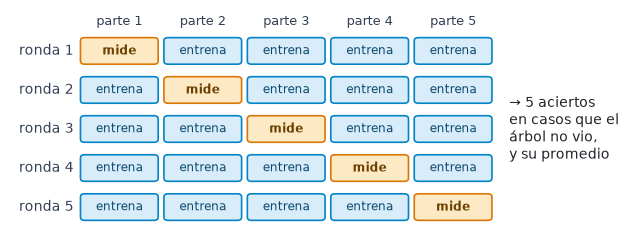

**Desglose del experimento.** La celda dibuja el árbol, con la rama del «sí» siempre a la izquierda, y lista sus reglas: cada una dice a cuántos pasajeros se aplica y cuántos tienen la respuesta de la hoja. Al final, las 5 partes de la validación. En clase, use `PROFUNDIDAD = 3`.

* Ejecute la siguiente celda para inducir el árbol.

In [ ]:
# ✏️ La profundidad del árbol: cuántas preguntas seguidas puede hacer (un entero, o None para «sin límite»)
PROFUNDIDAD = 3
arbol = a.arbol(titanic, PROFUNDIDAD)

**Análisis.** Lea el árbol de arriba hacia abajo: ¿aparece «mujeres y niños primero»? ¿Qué les pregunta a las mujeres, y qué a los varones después de la edad? «O desconocida»: los pasajeros sin ese dato siguen por esa rama.

**✏️ Su análisis (secciones 1 y 2).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué regla del árbol coincide con la del experto, y cuál agrega algo que el experto no dijo? ¿Por qué el árbol acierta más que la regla del experto, si ella se escribió con conocimiento del protocolo?*

*Escriba aquí.*

<a id='3'></a>
## 3 - ¿Qué tan profundo?

Si un árbol crece sin límite, deja a cada pasajero casi solo en su hoja: se aprende de memoria los casos, con su ruido. Es el **sobreajuste** de la Sesión 5: acierta casi todo en entrenamiento y menos en los casos nuevos. La profundidad máxima es el freno más simple; otros son pedir un mínimo de casos por hoja o podar el árbol: quitarle las ramas que casi no ayudan.

**Desglose del experimento.** Para cada profundidad de la lista, la celda mide el acierto con los pasajeros con que el árbol aprendió (entrenamiento) y con la validación cruzada, y cuenta sus hojas, es decir, sus reglas. `None` es «sin límite» (∞ en la gráfica). Puede agregar profundidades separadas por comas: `[1, 2, 3, 4, 5, 8, 12, None]`. El ± de la «variación entre partes» es la desviación estándar entre las 5 partes, no el rango; una diferencia menor puede ser azar.

* Ejecute la siguiente celda para comparar las profundidades.

In [ ]:
# ✏️ Las profundidades que se comparan (None = sin límite)
PROFUNDIDADES = [1, 2, 3, 5, 8, None]
curva = a.curva_profundidad(titanic, PROFUNDIDADES)

**Análisis.** La curva azul, de entrenamiento, siempre sube. La ámbar, de validación, sube hasta un punto y luego baja: desde ahí el árbol memoriza. Mire también las hojas: un árbol sin límite tiene cientos de reglas que nadie revisaría.

**✏️ Su análisis (sección 3).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué profundidad elegiría y por qué, con las cifras de la tabla? ¿Cuántas reglas tendría que revisar un experto en el árbol sin límite, y cuánto acierta ese árbol en pasajeros que no vio?*

*Escriba aquí.*

<a id='4'></a>
## 4 - Muchos árboles votan, y la pregunta del auditor

Un **ensamble** combina muchos modelos. En un **bosque aleatorio** (Breiman, 2001), cada árbol aprende con una muestra distinta de pasajeros y de columnas, y al final votan. En el **boosting por gradiente** (Friedman, 2001), cada árbol nuevo corrige los errores de los anteriores. En datos de tabla medianos suelen superar incluso a las redes profundas (Grinsztajn et ál., 2022); el precio es la explicación.

**Desglose del experimento.** La celda compara el árbol de la sección 2 con un bosque de 300 árboles y un boosting, con la misma validación cruzada; no siempre ganan los ensambles. «Lo que habría que leer» cuenta las reglas de cada modelo.

* Ejecute la siguiente celda para comparar el árbol con los ensambles. Tarda unos segundos.

In [ ]:
# Un árbol frente a un bosque aleatorio y un boosting, con la misma validación cruzada
comparacion = a.ensambles(titanic)

**La pregunta del auditor.** En la Sesión 1, un sistema experto respondía «¿por qué?» con su traza. Un árbol responde con su camino de preguntas; un bosque, con un conteo de votos.

**Desglose del experimento.** `PASAJERO` describe a un pasajero inventado. En clase, ejecute la celda tal como está; en casa podrá cambiar sus datos.

<details>
<summary><b>Pista:</b> los valores válidos de <code>PASAJERO</code></summary>

* `clase`: 1, 2 o 3, sin comillas ni «.ª». `sexo`: `"mujer"` u `"hombre"`, entre comillas.
* `edad` y `tarifa`: números con punto decimal, como `8.05`, o `None`, sin comillas, si el dato es desconocido. Con coma decimal, `8,05`, Python da un `SyntaxError`.
* `hermanos_o_conyuge` y `padres_o_hijos`: enteros, de 0 a 10.
* `puerto`: `"Southampton"`, `"Cherbourg"` o `"Queenstown"`, entre comillas.

</details>

* Ejecute la celda tal como está.

In [ ]:
# ✏️ Un pasajero inventado: cambie sus datos (None = dato desconocido)
PASAJERO = {"clase": 3, "sexo": "hombre", "edad": 40, "hermanos_o_conyuge": 0, "padres_o_hijos": 0,
            "tarifa": 8.05, "puerto": "Southampton"}
a.pregunta_del_auditor(titanic, PASAJERO)

**Análisis.** En el árbol, el auditor puede discutir cada pregunta del camino; en el bosque recibe un voto de cientos de árboles. Rudin (2019) propone preferir un modelo interpretable en decisiones de alto impacto cuando acierta casi igual.

**✏️ Su análisis (sección 4).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Le ganó el bosque al árbol en aciertos, y es esa diferencia mayor que la variación entre partes? Si usted fuera el auditor, ¿con cuál modelo se quedaría para explicar una decisión sobre una persona, y por qué?*

*Escriba aquí.*

<a id='5'></a>
## 5 - Un LLM como experto sin datos

Un LLM ha leído mucho sobre el Titanic. ¿Escribe reglas tan buenas como las del árbol, sin ver los datos? La celda le pide de 3 a 5 reglas en un formato fijo, una **lista de decisión** que se aplica en orden, como un sistema experto, y las aplica a los 1309 pasajeros. Una línea fuera de formato se marca «no válida», sin adivinar qué quiso decir.

> **Nota:** el LLM probablemente leyó sobre el Titanic, y quizás sobre este conjunto, un clásico de los cursos. Si acierta, puede ser por **recuerdo** y no por razonamiento (sección 7.1).

**Desglose del experimento.** Con respuestas grabadas, verá la respuesta real de Claude Haiku 5.5 del 29-oct-2026. La instrucción y la respuesta están en el desplegable de la salida.

* Ejecute la siguiente celda para pedirle las reglas al LLM.

In [ ]:
# El LLM escribe reglas sin ver los datos; el notebook las aplica a los 1309 pasajeros
reglas_titanic = r.pedir_reglas(llm, titanic, "titanic")

**Análisis.** ¿Qué reglas del LLM coinciden con las del árbol? «Decide sobre» cuenta los pasajeros a los que llega cada regla, los que no atrapó una regla anterior; una regla que decide sobre muchos y acierta poco hace más daño que una rara. Una condición de edad no se cumple si la edad es desconocida.

**✏️ Su análisis (sección 5).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Acertó el LLM más o menos que la regla del experto y que el árbol, y qué regla suya acierta en menor proporción? Si mañana llegan los datos de otro naufragio, ¿qué ventaja tiene el árbol sobre el LLM?*

*Escriba aquí.*

<a id='6'></a>
## 6 - Decidir con costos: el German Credit

En un banco, aprobar un crédito a quien no paga cuesta más que rechazar a quien sí pagaría. El **Statlog German Credit** (Hofmann, 1994) trae 1000 solicitudes anónimas de un banco alemán, 300 de malos pagadores, y una **matriz de costos**:

| real ↓ · decisión → | aprobar | rechazar |
| :--- | :---: | :---: |
| buen pagador | 0 | 1 |
| mal pagador | 5 | 0 |

Un bosque aleatorio estima para cada solicitud la probabilidad de que sea de un mal pagador; el **umbral** decide desde qué probabilidad se rechaza. Con esta matriz, rechazar conviene desde 1/6 ≈ 0,167: es el **umbral teórico**.

<details>
<summary><b>Para profundizar:</b> el umbral que minimiza el costo</summary>

Si p es la probabilidad de ser mal pagador, rechazar cuesta en promedio (1 − p) × 1, y aprobar, p × 5. Rechazar conviene cuando cuesta menos, es decir, desde p = 1 / (1 + 5) = 1/6 ≈ 0,167. En general, el umbral es c<sub>FP</sub> / (c<sub>FP</sub> + c<sub>FN</sub>), donde c<sub>FP</sub> es el costo de rechazar a un buen pagador y c<sub>FN</sub> el de aprobar a uno malo (Elkan, 2001). Funciona si las probabilidades del modelo son confiables. Un bosque no siempre las da bien calibradas, y por eso la curva muestra también el umbral de menor costo con estos datos.

</details>

> **Nota:** se excluyen «estado civil y sexo», que no permite saber el sexo, y «trabajador extranjero», codificada al revés (Fabris et ál., 2022). Son solicitudes de 1973 a 1975 que recibieron el crédito: el modelo no sabe nada de las rechazadas. Es una decisión de negocio, no un juicio sobre grupos de personas.

* Ejecute la siguiente celda para leer las solicitudes y estimar sus probabilidades.

In [ ]:
# Leer las 1000 solicitudes y estimar la probabilidad de que cada una sea de un mal pagador
credito = c.cargar_credito()

**Desglose del experimento.** Agregue a `UMBRALES` el umbral teórico, `1/6`. La celda muestra la matriz de cada umbral con el costo de cada casilla, una tabla con «aprobar a todos» y «rechazar a todos» como referencia, y la curva del costo según el umbral.

<details>
<summary><b>Pista:</b> cómo escribir la lista</summary>

`UMBRALES = [0.5, 1/6]`: todos dentro de los mismos corchetes, separados por comas, con punto decimal y sin comillas; 1/6 se escribe como una división. `[0.5] [1/6]` da un `TypeError`.

</details>

* Agregue 1/6 a `UMBRALES` y ejecute la celda.

In [ ]:
# ✏️ El costo de cada error y los umbrales que se comparan
COSTO_MAL_APROBADO = 5      # aprobar a un mal pagador
COSTO_BUEN_RECHAZADO = 1    # rechazar a un buen pagador
UMBRALES = [0.5]            # agregue el umbral teórico, 1/6
decision = c.decidir_con_costos(credito, UMBRALES, COSTO_MAL_APROBADO, COSTO_BUEN_RECHAZADO)

**Análisis.** Compare los aciertos con el costo total: si el umbral que más acierta no es el que menos cuesta, contar aciertos no era la medida. Compare también con «rechazar a todos». En la curva, el anillo verde marca el umbral de menor costo con estos datos; si cae lejos del teórico, las probabilidades del bosque no están **calibradas**: de cada 100 solicitudes a las que da 0,2, no son unas 20 las de malos pagadores.

**✏️ Su análisis (sección 6).** *En clase, responda solo la primera pregunta, en una frase; la otra, en casa. ¿Qué umbral elegiría para el banco y por qué, con el costo total y los aciertos de la tabla? En su organización, ¿qué error cuesta más, y quién debería decidir esa matriz de costos: quien construye el modelo o quien dirige el negocio?*

*Escriba aquí.*

<a id='7'></a>
## 7 - Para casa: la memoria del LLM, la fuga, otra matriz y sus casos

<a id='7-1'></a>
### 7.1 - ¿Recuerda el LLM el Titanic?

Si el LLM acertó por recuerdo, sus reglas deberían cambiar al quitarle el nombre del barco. La celda le pide las mismas reglas para «un barco de pasajeros que naufragó hace más de un siglo», con los puertos como A, B y C.

**Desglose del experimento.** Compare esta tabla de reglas con la de la sección 5. Si son casi iguales, el LLM aplica un conocimiento general, como el protocolo marítimo; si cambian mucho, el nombre del Titanic pesaba. Ninguna de las dos pruebas demuestra que el LLM razone: la clase del pasaje o la tarifa en libras siguen dando pistas.

* Para casa: ejecute la celda y compare las reglas con las de la sección 5.

In [ ]:
# Las mismas reglas, sin nombrar el barco
reglas_anonimo = r.pedir_reglas(llm, titanic, "anonimo")

<a id='7-2'></a>
### 7.2 - La fuga de información

**Desglose del experimento.** La celda agrega dos datos que revelan la respuesta, el bote salvavidas y el cuerpo recuperado, e induce otra vez un árbol de profundidad 3. Este árbol no se anota en el CSV.

* Para casa: ejecute la celda y compare el acierto con el de la sección 2.

In [ ]:
# El mismo árbol, con dos datos que revelan la respuesta: el bote salvavidas y el cuerpo recuperado
titanic_con_fuga = a.cargar_titanic(con_fuga=True, mostrar=False)
fuga = a.arbol(titanic_con_fuga, 3, registrar=False)

**Análisis.** Un acierto tan alto no es un gran modelo: es una trampa. ¿Qué pregunta hace primero el árbol? Ese dato solo existe después del naufragio; un modelo que lo usa no sirve para decidir antes. En la Sesión 5, los modos de falla del AI4I eran el mismo tipo de fuga.

<a id='7-3'></a>
### 7.3 - Otra matriz de costos

Si aprobar a un mal pagador costara 10 veces más que rechazar a uno bueno, el umbral teórico sería 1 / (1 + 10) = 1/11.

**Desglose del experimento.** Cambie `COSTO_MAL_APROBADO_2` a 10 y agregue 1/11 a la lista de umbrales. Compare la curva con la de la sección 6: ¿se acerca el umbral de menor costo al teórico? Recuerde que el umbral teórico supone probabilidades calibradas, y que un modelo puede estar bien calibrado en unas probabilidades y mal en otras.

* Para casa: cambie el costo y los umbrales, y ejecute la celda.

In [ ]:
# ✏️ Para casa: otra matriz de costos y sus umbrales
COSTO_MAL_APROBADO_2 = 5
COSTO_BUEN_RECHAZADO_2 = 1
UMBRALES_2 = [1/6]
decision_2 = c.decidir_con_costos(credito, UMBRALES_2, COSTO_MAL_APROBADO_2, COSTO_BUEN_RECHAZADO_2)

<a id='7-4'></a>
### 7.4 - Sus propios casos (trabajo independiente TI-1)

El TI-1 le pide escribir de 40 a 60 casos de la decisión de su sistema experto de la Sesión 1, con la conclusión que daría un experto, y comparar las reglas que induce un árbol con las suyas. Esta sección lo hace sin tocar el código, y su tiempo es parte del TI-1; el formato está en `mis_casos/LEEME.md`. El archivo `mis_casos/ejemplo.csv` trae 40 casos inventados del diagnóstico de MantenIA, con la vibración, el ruido, la temperatura del rodamiento y la desalineación de las reglas R1 a R4 de la Sesión 1: úselo para probar la sección antes de escribir los suyos.

**Desglose del experimento.** La primera celda lee su archivo y compara árboles de profundidad 2, 3 y 4 con validación cruzada. Si alguna conclusión tiene menos de 5 casos, usa menos partes y lo avisa. Sus casos no se anotan en `resultados_6A.csv`, pero los primeros quedan a la vista en el notebook que entrega: por eso no deben tener datos personales.

* Para casa: escriba la ruta de su archivo y ejecute la celda.

In [ ]:
# ✏️ Para casa: la ruta de su archivo de casos (el ejemplo sirve para probar)
RUTA_MIS_CASOS = "mis_casos/ejemplo.csv"
mis_casos = a.cargar_casos(RUTA_MIS_CASOS)
if mis_casos is not None:
    a.curva_profundidad(mis_casos, [2, 3, 4])

**Desglose del experimento.** Escriba la profundidad que eligió con la tabla anterior. La celda dibuja ese árbol y lista sus reglas, en los términos de sus columnas: compárelas con las de su sistema experto.

* Para casa: escriba la profundidad y ejecute la celda.

In [ ]:
# ✏️ Para casa: la profundidad que eligió para sus casos
PROFUNDIDAD_MIS_CASOS = 3
if mis_casos is not None:
    arbol_mis_casos = a.arbol(mis_casos, PROFUNDIDAD_MIS_CASOS)

**Desglose del experimento.** ¿Son estables sus reglas? La celda quita `QUITAR_CASOS` casos elegidos al azar, siempre los mismos, e induce otra vez el árbol. Si las reglas cambian mucho, 40 casos no bastan para confiar en ellas.

* Para casa: ejecute la celda y compare las reglas con las de la celda anterior.

In [ ]:
# ✏️ Para casa: cuántos casos quitar al azar para probar la estabilidad de las reglas
QUITAR_CASOS = 5
if mis_casos is not None:
    a.estabilidad(mis_casos, QUITAR_CASOS, PROFUNDIDAD_MIS_CASOS)

<a id='intentelo'></a>
### Inténtelo usted mismo (opcional)

Todo se hace en las celdas ✏️ ya usadas. Después, vuelva a los valores de clase, para que sus análisis coincidan con las salidas:
* En la sección 1, busque la edad de niño que más acierta; después vuelva a 14.
* En la sección 2, pruebe `PROFUNDIDAD = 2`: ¿qué reglas se pierden, y cuánto baja el acierto? Después vuelva a 3.
* En la sección 4, describa a un pasajero de 2.ª clase sin edad conocida, con `"edad": None`: ¿qué camino sigue en el árbol?

**✏️ Su análisis (sección 7).** *Para casa. ¿Cambiaron las reglas del LLM al quitarle el nombre del barco, y qué concluye de eso? ¿Qué pregunta hizo primero el árbol con la fuga, y por qué no serviría para decidir? Con la matriz de 10 a 1, ¿dónde quedó el umbral de menor costo? Si probó sus casos, ¿cuántas reglas cambiaron al quitar 5?*

*Escriba aquí.*

<a id='8'></a>
## 8 - Entrega y criterios

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y el archivo `resultados_6A.csv`, que anota una fila por pasajero y por método. Uno por pareja, por el canal del curso, al inicio de la semana 4.

**Resultados reproducibles.** Antes de terminar los análisis, ejecute el notebook completo (**Reiniciar** y **Ejecutar todo**) con sus configuraciones finales. Los árboles y los ensambles usan la semilla 7, así que sus números se repiten. Las respuestas de un LLM por API o local pueden cambiar de una ejecución a otra: si usó una de esas vías, revise sus análisis de las secciones 5 y 7.1 contra las salidas finales.

**Desglose.** Escriba los nombres de la pareja en `PAREJA`.

* Escriba los nombres y ejecute la celda para guardar `resultados_6A.csv`.

In [ ]:
# ✏️ Los nombres de la pareja, y guardar el CSV de resultados
PAREJA = "Nombre 1 y Nombre 2"
a.exportar_csv(PAREJA)

| Criterio | Peso |
| :--- | :--- |
| La regla del experto y el primer árbol: las reglas que coinciden y las que el árbol agrega (secciones 1 y 2) | 25 % |
| La profundidad y la validación cruzada: la elección justificada con la tabla (sección 3) | 20 % |
| El ensamble, la pregunta del auditor y las reglas del LLM, con su lectura crítica (secciones 4 y 5) | 25 % |
| El costo del error: el umbral elegido con la matriz de costos (sección 6) | 20 % |
| La parte de casa: la memoria del LLM, la fuga y otra matriz (sección 7), con análisis coherentes con las salidas | 10 % |

### ✏️ Declaración de uso de asistentes de IA

Declare si usaron asistentes de IA y para qué: por ejemplo, para entender un concepto o redactar un análisis.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted indujo un árbol de decisión sin escribir código y lo leyó como una base de reglas: redescubrió «mujeres y niños primero» y encontró matices que el experto no escribió. Vio que un árbol sin límite memoriza, que la validación cruzada mide en casos no vistos, que un ensamble acierta casi igual pero ya no se explica, y que un LLM escribe reglas plausibles que hay que poner a prueba con datos. Con el German Credit vio que acertar más no es perder menos: el umbral se elige con los costos del negocio.

En el **Laboratorio 6B**, el agente ya no aprende de ejemplos con la respuesta, sino de las recompensas de sus acciones. En el **trabajo independiente TI-1**, la sección 7.4 compara las reglas de su sistema experto de la Sesión 1 con las que induce un árbol. En el **proyecto del curso**, la guía de decisión de la charla de cierre le ayudará a elegir entre reglas escritas, un árbol, un ensamble u otra técnica.

<a id='referencias'></a>
## Referencias

* Quinlan, J. R. (1986). Induction of decision trees. *Machine Learning* 1(1), 81–106. [DOI](https://doi.org/10.1007/BF00116251)
* Breiman, L., Friedman, J. H., Olshen, R. A. y Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
* Breiman, L. (2001). Random forests. *Machine Learning* 45(1), 5–32. [DOI](https://doi.org/10.1023/A:1010933404324)
* Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics* 29(5), 1189–1232. [DOI](https://doi.org/10.1214/aos/1013203451)
* Kohavi, R. (1995). A study of cross-validation and bootstrap for accuracy estimation and model selection. *IJCAI-95*, 1137–1143. [IJCAI](https://www.ijcai.org/proceedings/1995/147)
* Elkan, C. (2001). The foundations of cost-sensitive learning. *IJCAI-01*, 973–978. [IJCAI](https://www.ijcai.org/proceedings/2001/133)
* Rudin, C. (2019). Stop explaining black box machine learning models for high stakes decisions and use interpretable models instead. *Nature Machine Intelligence* 1(5), 206–215. [arXiv](https://arxiv.org/abs/1811.10154)
* Grinsztajn, L., Oyallon, E. y Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS* 35. [NeurIPS](https://proceedings.neurips.cc/paper_files/paper/2022/hash/0378c7692da36807bdec87ab043cdadc-Abstract-Datasets_and_Benchmarks.html)
* Datos: titanic3, cortesía del Departamento de Bioestadística de la Universidad Vanderbilt, [hbiostat.org/data](https://hbiostat.org/data/) · Hofmann, H. (1994). Statlog (German Credit Data). UCI, CC BY 4.0. [DOI](https://doi.org/10.24432/C5NC77) · Fabris, A. et ál. (2022). Algorithmic fairness datasets: the story so far. *Data Mining and Knowledge Discovery*. [arXiv](https://arxiv.org/abs/2202.01711)
* scikit-learn: [árboles de decisión](https://scikit-learn.org/stable/modules/tree.html), [validación cruzada](https://scikit-learn.org/stable/modules/cross_validation.html) y [ensambles](https://scikit-learn.org/stable/modules/ensemble.html).